Please read carefully the following lines before proceeding with the exercise:
---
#### 1. Make your own copy of this notebook to your Drive. Work on that copy instead.
#### 2. Make sure you add a shortcut of the [CV_6-CNN](https://drive.google.com/drive/folders/1mwSMGZUfw-CgGwA9NWBdnFCoQWjEPOPO?usp=sharing) shared folder to your Drive.
#### 3. Any files you wish to create can only be saved to your Drive, not in the shared folder. For that reason the second cell makes a copy of the shared folder to your drive ('copy_CV_6-CNN').
#### 4. Don't forget to change your Runtime Type to "GPU".
#### 5. Remember that each time you close this tab, your Google Drive is unmounted and all variables are lost.


Have fun :)



In [1]:
from google.colab import drive
drive.mount('/content/drive')

ModuleNotFoundError: No module named 'google'

In [ ]:
!cp -r '/content/drive/MyDrive/CV_6-CNN' '/content/drive/MyDrive/copy_CV_6-CNN'

In [14]:
import sys
# Αυτό λέει στην Python που τρέχει ΤΩΡΑ το notebook, να καλέσει τον δικό της pip
!{sys.executable} -m pip install torch torchvision
!{sys.executable} -m pip install pycocotools

Defaulting to user installation because normal site-packages is not writeable


In [18]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from datetime import datetime
import matplotlib.pyplot as plt
plt.style.use('dark_background')
plt.rcParams['image.cmap'] = 'gist_gray'
from torch.utils.data import DataLoader
from torchvision import models
from torchvision import transforms
from matplotlib.patches import Rectangle
from torchvision.datasets import CocoDetection
device = torch.device("cpu")

Dataset

In [19]:
dataset_val = CocoDetection(root='./val2017/',
                            annFile='./annotations_trainval2017/annotations/instances_val2017.json',
                            transform=transforms.Compose([transforms.ToTensor(),transforms.Resize((320,213))]))


loading annotations into memory...
Done (t=0.33s)
creating index...
index created!


Dataloader

In [20]:
val_dataloader = DataLoader(dataset_val, batch_size=1, shuffle=False, num_workers=0)

Faster-RCNN with ResNet50 backbone CNN and FPN

In [29]:
model = models.detection.fasterrcnn_resnet50_fpn(pretrained=True,num_classes=91).to(device)

/Users/ermisefthymiou/Library/Python/3.9/lib/python/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/ermisefthymiou/Library/Python/3.9/lib/python/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1`. You can also use `weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


SSD with VGG16 backbone CNN

In [34]:
model = models.detection.ssd300_vgg16(pretrained=True,num_classes=91).to(device)

/Users/ermisefthymiou/Library/Python/3.9/lib/python/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/ermisefthymiou/Library/Python/3.9/lib/python/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=SSD300_VGG16_Weights.COCO_V1`. You can also use `weights=SSD300_VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [35]:
from tqdm import tqdm # fancy and unnecessary library to add loading bar for the loop

model.eval() # switch to evaluation mode, 

all_detections = []
all_targets = []
for imgs_batch,targets_batch in tqdm(val_dataloader):
    # Move imgs_batch and targets_batch to device
    imgs_batch = [imgs.to(device) for imgs in imgs_batch]
    
    targets_batch = [targets for targets in targets_batch]

    # Transform targets to COCO format.
    new_targets_batch = []
    targets_batch = [targets_batch]

    for targets in targets_batch:   
        new_targets = {'boxes':[],'labels':[]}
        for t in targets:
            x,y,w,h = [s for s in t['bbox']]
            new_targets['boxes'].append(torch.Tensor([x, y, x+w, y+h]))
            new_targets['labels'].append(t['category_id'])
        if len(new_targets['boxes']) > 0:
            new_targets['boxes'] = torch.stack(new_targets['boxes'], dim=0)
        new_targets['labels'] = torch.Tensor(new_targets['labels']).long()
        new_targets_batch.append(new_targets)
    targets_batch = new_targets_batch

    # Forward pass
    with torch.no_grad():
        detections_batch = model(imgs_batch)

    del imgs_batch 
    

    # Keep detections and targets to compare
    all_targets.append(targets_batch)
    all_detections.append(detections_batch)

# torch.save(all_detections, 'all_detections_faster.pth')
# torch.save(all_targets, 'all_targets_faster.pth')

100%|██████████| 5000/5000 [10:19<00:00,  8.07it/s]


/var/folders/08/qxpszd4x7lj7gf8wkhqwv2vh0000gn/T/ipykernel_4408/1378287814.py:131: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return float(np.trapz(Pc, Rc))


,Model,Precision@thr=0.5,Recall@thr=0.5,F1,mAP@IoU=0.5
0,Faster R-CNN,0.00522,0.004731,0.004963,0.000105
1,SSD,0.00522,0.004731,0.004963,0.000105


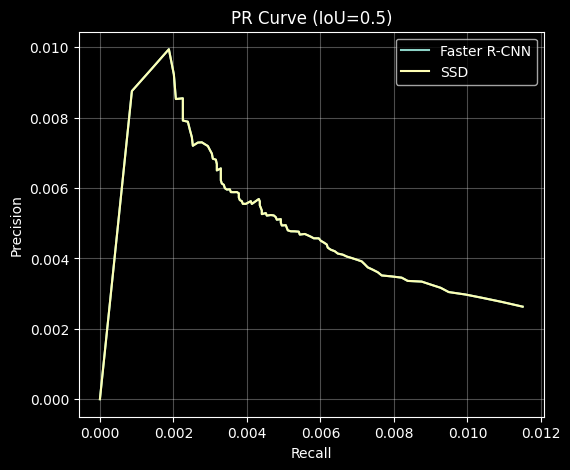

In [32]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

dets_faster = torch.load("all_detections_faster.pth", map_location="cpu")
tars_faster = torch.load("all_targets_faster.pth",    map_location="cpu")
dets_ssd    = torch.load("all_detections_SSD.pth",    map_location="cpu")
tars_ssd    = torch.load("all_targets_SSD.pth",       map_location="cpu")

def flatten_batches(all_dets, all_tars):
    dets, tars = [], []
    for db, tb in zip(all_dets, all_tars):
        # db: list of dicts (per image)
        # tb: usually list of dicts (per image) when batch_size=1 in your notebook
        if isinstance(db, list):
            dets.extend(db)
        else:
            dets.append(db)

        if isinstance(tb, list):
            tars.extend(tb)
        else:
            tars.append(tb)
    # keep aligned
    n = min(len(dets), len(tars))
    return dets[:n], tars[:n]

dets_faster, tars_faster = flatten_batches(dets_faster, tars_faster)
dets_ssd,    tars_ssd    = flatten_batches(dets_ssd,    tars_ssd)


def iou_matrix(a, b):
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)), dtype=np.float32)
    a = a.astype(np.float32); b = b.astype(np.float32)

    x1 = np.maximum(a[:, None, 0], b[None, :, 0])
    y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2])
    y2 = np.minimum(a[:, None, 3], b[None, :, 3])

    inter = np.maximum(0, x2 - x1) * np.maximum(0, y2 - y1)
    area_a = np.maximum(0, a[:, 2] - a[:, 0]) * np.maximum(0, a[:, 3] - a[:, 1])
    area_b = np.maximum(0, b[:, 2] - b[:, 0]) * np.maximum(0, b[:, 3] - b[:, 1])
    union = area_a[:, None] + area_b[None, :] - inter
    return inter / np.maximum(union, 1e-9)

def greedy_tp_fp_fn(pb, ps, gb, iou_thr=0.5):
    # match preds->GT by best IoU, each GT at most once (per class)
    if len(pb) == 0 and len(gb) == 0: return 0, 0, 0
    if len(pb) == 0: return 0, 0, len(gb)
    if len(gb) == 0: return 0, len(pb), 0

    order = np.argsort(-ps)
    pb, ps = pb[order], ps[order]
    ious = iou_matrix(pb, gb)
    used = np.zeros(len(gb), dtype=bool)

    tp = fp = 0
    for i in range(len(pb)):
        j = np.argmax(np.where(used, -1.0, ious[i]))
        best = ious[i, j] if not used[j] else -1.0
        if best >= iou_thr:
            tp += 1
            used[j] = True
        else:
            fp += 1
    fn = int((~used).sum())
    return tp, fp, fn

def eval_detector(dets, tars, iou_thr=0.5, score_thr_point=0.5, sweep=np.linspace(0,1,101)):
    gt_classes = set()
    for t in tars:
        for c in t["labels"].tolist():
            gt_classes.add(int(c))
    gt_classes = sorted(gt_classes)

    def to_np(x):
        if isinstance(x, torch.Tensor):
            return x.detach().cpu().numpy()
        elif isinstance(x, list):
            return np.array(x)
        else:
            return np.asarray(x)

    def counts_at_thr(thr, cls=None):
        TP=FP=FN=0
        for d,t in zip(dets,tars):
            pb = to_np(d["boxes"])
            pl = to_np(d["labels"]).astype(int)
            ps = to_np(d["scores"])

            gb = to_np(t["boxes"])
            gl = to_np(t["labels"]).astype(int)


            keep = ps >= thr
            pb, pl, ps = pb[keep], pl[keep], ps[keep]

            classes = [cls] if cls is not None else (set(pl.tolist()) | set(gl.tolist()))
            for c in classes:
                pbc = pb[pl==c]; psc = ps[pl==c]
                gbc = gb[gl==c]
                tp, fp, fn = greedy_tp_fp_fn(pbc, psc, gbc, iou_thr=iou_thr)
                TP += tp; FP += fp; FN += fn
        return TP,FP,FN

    TP,FP,FN = counts_at_thr(score_thr_point, cls=None)
    P = TP/(TP+FP+1e-9)
    R = TP/(TP+FN+1e-9)
    F1 = 2*P*R/(P+R+1e-9)

    Ps, Rs = [], []
    for thr in sweep:
        TP,FP,FN = counts_at_thr(thr, cls=None)
        Ps.append(TP/(TP+FP+1e-9))
        Rs.append(TP/(TP+FN+1e-9))
    Ps, Rs = np.array(Ps), np.array(Rs)


    def ap_from_pr(Rc, Pc):
        o = np.argsort(Rc)
        Rc, Pc = Rc[o], Pc[o]
        Pc = np.maximum.accumulate(Pc[::-1])[::-1]   # precision envelope
        return float(np.trapz(Pc, Rc))


    ap_per_class = {}
    for c in gt_classes:
        Pc, Rc = [], []
        for thr in sweep:
            TP,FP,FN = counts_at_thr(thr, cls=c)
            Pc.append(TP/(TP+FP+1e-9))
            Rc.append(TP/(TP+FN+1e-9))
        ap_per_class[c] = ap_from_pr(np.array(Rc), np.array(Pc))
    mAP = float(np.mean(list(ap_per_class.values()))) if ap_per_class else 0.0

    return {"P":float(P), "R":float(R), "F1":float(F1), "PR_P":Ps, "PR_R":Rs, "mAP":mAP}

IOU = 0.5
POINT_THR = 0.5
SWEEP = np.linspace(0,1,101)

res_faster = eval_detector(dets_faster, tars_faster, iou_thr=IOU, score_thr_point=POINT_THR, sweep=SWEEP)
res_ssd    = eval_detector(dets_ssd,    tars_ssd,    iou_thr=IOU, score_thr_point=POINT_THR, sweep=SWEEP)


df = pd.DataFrame([
    ["Faster R-CNN", res_faster["P"], res_faster["R"], res_faster["F1"], res_faster["mAP"]],
    ["SSD",          res_ssd["P"],    res_ssd["R"],    res_ssd["F1"],    res_ssd["mAP"]],
], columns=[f"Model", f"Precision@thr={POINT_THR}", f"Recall@thr={POINT_THR}", "F1", f"mAP@IoU={IOU}"])
display(df)


plt.figure(figsize=(6,5))
plt.plot(res_faster["PR_R"], res_faster["PR_P"], label="Faster R-CNN")
plt.plot(res_ssd["PR_R"],    res_ssd["PR_P"],    label="SSD")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title(f"PR Curve (IoU={IOU})")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()